# Precipitación anual: señal climática para evaluar exposición

## Resumen
El último año completo disponible es 2025 y el comparativo comprende 10 ciudades.

Un equipo de riesgo puede comparar lluvia anual con una referencia histórica antes de solicitar datos geográficos de cartera.

**Alcance:** NASA POWER es una estimación meteorológica en puntos de referencia, no estación de una finca. No hay exposición georreferenciada ni default; esto no estima PD, pérdida crediticia, inundaciones ni causalidad.

**Hallazgo del corte:** En los diez puntos analizados, 2025 supera la media 2001–2020; la referencia está completa para las diez ciudades. La diferencia descriptiva no establece tendencia ni exposición crediticia.

## Contexto y método
Aplicación descriptiva reproducible. Las cantidades son agregadas a partir del archivo citado; no se infiere causalidad ni desempeño institucional.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').exists())
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Datos
[NASA POWER](https://power.larc.nasa.gov/): totales anuales derivados para diez coordenadas urbanas, a partir del companion `observed-nasa-power-climate-index`. Solo años completos; referencia propia 2001–2020 de 20 años completos por ciudad. Esa ventana difiere de la ventana 2000–2019 utilizada en el companion original, por lo que los porcentajes no son comparables directamente. Las estimaciones se expresan en milímetros y no son observaciones de estaciones. Python con pandas, matplotlib y Jupyter; ejecutar desde el repositorio.

In [2]:
source = '03-financial-risk/01-credit-risk/credit-portfolio-strategy/climate-parametric-pricing/observed-nasa-power-climate-index/results/annual_precipitation.csv'
p = root / source
print('Archivo:', source, '\nSHA-256:', hashlib.sha256(p.read_bytes()).hexdigest())

Archivo: 03-financial-risk/01-credit-risk/credit-portfolio-strategy/climate-parametric-pricing/observed-nasa-power-climate-index/results/annual_precipitation.csv 
SHA-256: 257030e0111f3a20aa2bf07fccc8fe0f9d0b4f0dd13a525211eea7c4e8e1a1c9


## Resultados

Años completos por ciudad en referencia: 20 a 20
Año comparable más reciente: 2025 | ciudades: 10


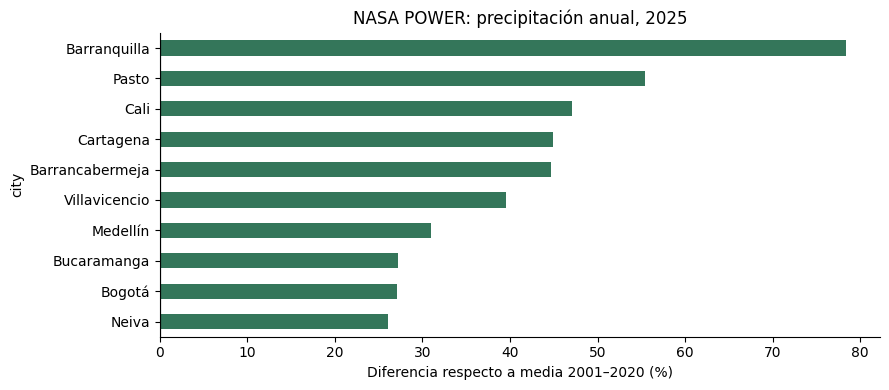

,city,year,precipitation_mm,baseline_mm,desviacion_pct
214,Neiva,2025,1659.74,1316.3340,26.088060
79,Bogotá,2025,2063.79,1624.3060,27.056725
106,Bucaramanga,2025,1585.61,1246.4680,27.208240
187,Medellín,2025,2974.28,2270.7365,30.983053
268,Villavicencio,2025,3400.87,2437.8095,39.505158
25,Barrancabermeja,2025,2323.89,1606.3935,44.665052
160,Cartagena,2025,1985.60,1369.9025,44.944622
133,Cali,2025,1502.83,1021.8790,47.065357
241,Pasto,2025,1613.30,1037.6640,55.474219
52,Barranquilla,2025,2008.83,1126.3005,78.356487


In [3]:
annual = pd.read_csv(root / source)
annual = annual[annual.complete_year.astype(str).str.lower().eq('true')].copy()
assert not annual.duplicated(['city','year']).any(), 'Ciudad-año duplicado'
assert (annual.precipitation_mm >= 0).all(), 'Precipitación inválida'
base = annual[annual.year.between(2001,2020)]
counts = base.groupby('city').year.nunique()
print('Años completos por ciudad en referencia:', counts.min(), 'a', counts.max())
assert (counts == 20).all(), 'Referencia incompleta'
reference = base.groupby('city').precipitation_mm.mean().rename('baseline_mm')
assert (reference > 0).all()
joined = annual.join(reference, on='city').dropna(subset=['baseline_mm'])
joined['desviacion_pct'] = 100 * (joined.precipitation_mm / joined.baseline_mm - 1)
last_year = int(joined.year.max()); view=joined[joined.year.eq(last_year)].sort_values('desviacion_pct')
print('Año comparable más reciente:', last_year, '| ciudades:', len(view))
view.plot.barh(x='city', y='desviacion_pct', legend=False, color='#34765a', xlabel='Diferencia respecto a media 2001–2020 (%)', title=f'NASA POWER: precipitación anual, {last_year}')
plt.axvline(0,color='black',linewidth=.8); plt.tight_layout(); plt.show()
view[['city','year','precipitation_mm','baseline_mm','desviacion_pct']]

## Variante: referencia robusta y posición empírica

Comparamos cada valor anual más reciente con la **mediana** 2001–2020, además de la media, y calculamos la proporción de los 20 años de referencia con precipitación menor o igual al valor más reciente: `Fₙ(x) = número de años ≤ x / 20`. Es una función de distribución empírica descriptiva ([NIST](https://www.itl.nist.gov/div898/software/dataplot/refman1/auxillar/ecdfplot.htm)); tiene resolución de 5 puntos porcentuales y no es probabilidad pronosticada, periodo de retorno ni riesgo de crédito. El supuesto de que el pasado representa el futuro puede fallar ante tendencia, dependencia y cambios de clima. El [IPCC AR6](https://www.ipcc.ch/report/ar6/wg1/chapter/chapter-1/) exige además exposición y vulnerabilidad para valorar riesgo, y [NASA POWER](https://power.larc.nasa.gov/docs/methodology/) explica que los parámetros provienen de productos meteorológicos en grilla.

In [4]:
assert view.city.is_unique and len(view)>0
summary_rows=[]
for _, obs in view.iterrows():
    hist=base.loc[base.city.eq(obs.city),'precipitation_mm']
    assert len(hist)==20 and hist.notna().all()
    mediana=hist.median()
    assert mediana > 0
    summary_rows.append({'ciudad':obs.city,'anio':int(obs.year),'precipitacion_mm':obs.precipitation_mm,
                         'mediana_2001_2020_mm':mediana,'variacion_vs_mediana_pct':100*(obs.precipitation_mm/mediana-1),
                         'fraccion_referencia_menor_o_igual':(hist <= obs.precipitation_mm).mean(),
                         'anios_referencia':len(hist)})
ranked=pd.DataFrame(summary_rows).sort_values('fraccion_referencia_menor_o_igual',ascending=False)
print('Fracción empírica dentro de la referencia histórica; no representa un pronóstico.')
ranked.round(3)

Fracción empírica dentro de la referencia histórica; no representa un pronóstico.


,ciudad,anio,precipitacion_mm,mediana_2001_2020_mm,variacion_vs_mediana_pct,fraccion_referencia_menor_o_igual,anios_referencia
8,Pasto,2025,1613.30,1009.460,59.818,1.00,20
4,Villavicencio,2025,3400.87,2502.335,35.908,1.00,20
7,Cali,2025,1502.83,1065.060,41.103,0.95,20
1,Bogotá,2025,2063.79,1634.250,26.284,0.95,20
5,Barrancabermeja,2025,2323.89,1507.220,54.184,0.95,20
3,Medellín,2025,2974.28,2209.890,34.590,0.95,20
9,Barranquilla,2025,2008.83,922.040,117.868,0.85,20
2,Bucaramanga,2025,1585.61,1192.400,32.976,0.85,20
0,Neiva,2025,1659.74,1250.525,32.723,0.80,20
6,Cartagena,2025,1985.60,1233.605,60.959,0.80,20


## Interpretación y límites
NASA POWER es una estimación meteorológica en puntos de referencia, no estación de una finca. No hay exposición georreferenciada ni default; esto no estima PD, pérdida crediticia, inundaciones ni causalidad.

La cifra y la gráfica son descriptivas del corte disponible; las decisiones requieren datos propios, revisión de calidad y validación independiente.

**Acción siguiente:** contrastar con datos autorizados de la entidad, definir población y umbrales antes de cualquier decisión, y conservar la fecha y el hash del corte usado. Los controles de este notebook son de calidad local y no sustituyen revisión independiente.